# 07｜单文件 PPO 学习实验台：从局部验证到完整训练

这本 Notebook 有三个目标：

1. **读懂**：代码变量尽量和 $s_t,a_t,r_{t+1},v(s_t),v(s_{t+1})$ 一一对应。
2. **复现**：Actor–Critic、GAE、PPO loss、rollout、update 后面都有独立检查器；自己重写一部分后，不必先跑完整训练就能验证。
3. **实验**：所有训练状态都封装在 `train_once(config)` 内。改变参数后会创建全新的环境、网络和优化器，不会混入上一次运行的状态。

本文件仍然**不导入仓库 `src/` 下的任何实现**。默认 `FULL_CONFIG` 完整训练 200,000 步；如果正在调试自己的代码，先把训练入口切换为 `QUICK_CONFIG`。

推荐精读顺序：Actor–Critic → GAE → PPO loss → rollout → update → 完整训练。第一次可以直接 **Restart Kernel and Run All Cells**，随后再逐段重写。

## 1. Setup：依赖、参数与两种运行规模

依赖为 `gymnasium[mujoco]`、`numpy`、`torch` 和 `matplotlib`。项目环境中可运行：

```bash
uv pip install -e ".[notebook]"
```

Colab 中只需先运行 `%pip install "gymnasium[mujoco]>=1.2,<2"`。本任务的小型 MLP 使用 CPU 即可。

In [1]:
from __future__ import annotations

import math
import random
import time
from dataclasses import dataclass, replace
from typing import Callable

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.distributions import Normal


@dataclass(frozen=True)
class Config:
    env_id: str = "InvertedPendulum-v5"
    total_timesteps: int = 200_000
    rollout_steps: int = 2_048
    update_epochs: int = 10
    minibatch_size: int = 64
    gamma: float = 0.99
    gae_lambda: float = 0.95
    clip_coef: float = 0.2
    actor_lr: float = 3e-4
    critic_lr: float = 1e-3
    entropy_coef: float = 0.0
    value_coef: float = 0.5
    max_grad_norm: float = 0.5
    hidden_size: int = 64
    max_episode_steps: int = 1_000
    seed: int = 1
    device: str = "cpu"


FULL_CONFIG = Config()
QUICK_CONFIG = replace(
    FULL_CONFIG,
    total_timesteps=10_000,
    rollout_steps=512,
    update_epochs=2,
)


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


torch.set_num_threads(1)
plt.style.use("seaborn-v0_8-whitegrid")

print("PyTorch:", torch.__version__)
print("Gymnasium:", gym.__version__)
print("FULL_CONFIG updates:", math.ceil(FULL_CONFIG.total_timesteps / FULL_CONFIG.rollout_steps))
print("QUICK_CONFIG updates:", math.ceil(QUICK_CONFIG.total_timesteps / QUICK_CONFIG.rollout_steps))

PyTorch: 2.5.1+cpu
Gymnasium: 1.4.0
FULL_CONFIG updates: 98
QUICK_CONFIG updates: 20


## 2. Actor–Critic：从 $s_t$ 得到动作分布和 $v(s_t)$

Actor 输出高斯均值，`log_std` 是可训练参数。rollout 保存高斯采样得到的 `raw_action_t` 和旧 `log_prob_t`；只有送入环境时才把动作裁剪到 `[-3,3]`。Critic 输出标量 $v(s_t)$。

`check_actor_critic()` 不关心网络内部怎样写，只检查输入输出契约和梯度。以后你可以写 `MyActorCritic`，然后直接把类传进去验证。

In [2]:
def orthogonal_init(layer: nn.Module, gain: float = math.sqrt(2.0)) -> nn.Module:
    if isinstance(layer, nn.Linear):
        nn.init.orthogonal_(layer.weight, gain)
        nn.init.constant_(layer.bias, 0.0)
    return layer


def make_mlp(input_dim: int, hidden_size: int, output_dim: int, output_gain: float):
    network = nn.Sequential(
        nn.Linear(input_dim, hidden_size), nn.Tanh(),
        nn.Linear(hidden_size, hidden_size), nn.Tanh(),
        nn.Linear(hidden_size, output_dim),
    )
    for layer in network[:-1]:
        orthogonal_init(layer)
    orthogonal_init(network[-1], output_gain)
    return network


class ActorCritic(nn.Module):
    def __init__(self, obs_dim: int, action_dim: int, hidden_size: int = 64):
        super().__init__()
        self.actor_mean = make_mlp(obs_dim, hidden_size, action_dim, output_gain=0.01)
        self.log_std = nn.Parameter(torch.full((action_dim,), -0.5))
        self.critic = make_mlp(obs_dim, hidden_size, 1, output_gain=1.0)

    def distribution(self, observations_t: torch.Tensor) -> Normal:
        action_mean_t = self.actor_mean(observations_t)
        action_std = self.log_std.exp().expand_as(action_mean_t)
        return Normal(action_mean_t, action_std)

    @staticmethod
    def joint_log_prob(distribution: Normal, actions_t: torch.Tensor) -> torch.Tensor:
        # 多维动作的联合 log probability = 各动作维 log probability 之和
        return distribution.log_prob(actions_t).sum(dim=-1)

    def value(self, observations_t: torch.Tensor) -> torch.Tensor:
        return self.critic(observations_t).squeeze(-1)

    @torch.no_grad()
    def act(self, observations_t: torch.Tensor):
        distribution_t = self.distribution(observations_t)
        raw_actions_t = distribution_t.sample()
        old_log_probs_t = self.joint_log_prob(distribution_t, raw_actions_t)
        values_t = self.value(observations_t)
        return raw_actions_t, old_log_probs_t, values_t

    def evaluate_actions(self, observations_t: torch.Tensor, actions_t: torch.Tensor):
        # PPO 必须评价 rollout 中保存的同一批动作，不能在这里重新采样
        distribution_t = self.distribution(observations_t)
        new_log_probs_t = self.joint_log_prob(distribution_t, actions_t)
        entropies_t = distribution_t.entropy().sum(dim=-1)
        predicted_values_t = self.value(observations_t)
        return new_log_probs_t, entropies_t, predicted_values_t

    def actor_parameters(self):
        yield from self.actor_mean.parameters()
        yield self.log_std

    def critic_parameters(self):
        yield from self.critic.parameters()


def check_actor_critic(model_class=ActorCritic) -> None:
    test_model = model_class(obs_dim=4, action_dim=2, hidden_size=16)
    observations_t = torch.randn(5, 4)
    distribution_t = test_model.distribution(observations_t)
    raw_actions_t = distribution_t.sample()
    log_probs_t = test_model.joint_log_prob(distribution_t, raw_actions_t)
    values_t = test_model.value(observations_t)

    assert distribution_t.mean.shape == (5, 2)
    assert raw_actions_t.shape == (5, 2)
    assert log_probs_t.shape == (5,), "log_prob 应沿动作维 sum(-1)"
    assert values_t.shape == (5,), "Critic 应输出每个状态一个标量"

    loss = -log_probs_t.mean() + values_t.square().mean()
    loss.backward()
    assert any(parameter.grad is not None for parameter in test_model.actor_parameters())
    assert any(parameter.grad is not None for parameter in test_model.critic_parameters())
    print("Actor–Critic contract passed: shapes and gradients are correct.")


check_actor_critic(ActorCritic)

Actor–Critic contract passed: shapes and gradients are correct.


## 3. GAE：bootstrap mask 与 recursion mask 是两件事

TD error：

$$\delta_t=r_{t+1}+\gamma(1-\mathrm{terminated}_t)v(s_{t+1})-v(s_t)$$

- 真正终止时不使用 $v(s_{t+1})$。
- 时间截断时状态本身并没有终止，所以仍保留 bootstrap。

GAE 递推：

$$A_t=\delta_t+\gamma\lambda c_t A_{t+1},\qquad
c_t=1-(\mathrm{terminated}_t\lor\mathrm{truncated}_t)$$

无论终止还是截断，环境之后都会 reset，所以都必须令 $c_t=0$，防止 advantage 跨 episode 传播。若 rollout 只是在某个普通时间步结束，最后一步不是 done；它仍使用保存的 $v(s_{t+1})$，只是当前批次外没有更多 TD error 可继续递推。

In [3]:
def compute_gae(
    rewards_tp1: torch.Tensor,
    values_t: torch.Tensor,
    next_values_tp1: torch.Tensor,
    terminated_t: torch.Tensor,
    truncated_t: torch.Tensor,
    gamma: float,
    gae_lambda: float,
):
    advantages_t = torch.zeros_like(rewards_tp1)
    advantage_after_t = torch.zeros((), dtype=rewards_tp1.dtype, device=rewards_tp1.device)

    for t in reversed(range(rewards_tp1.shape[0])):
        bootstrap_mask_t = 1.0 - terminated_t[t].float()
        recursion_mask_t = 1.0 - torch.logical_or(terminated_t[t], truncated_t[t]).float()

        delta_t = (
            rewards_tp1[t]
            + gamma * bootstrap_mask_t * next_values_tp1[t]
            - values_t[t]
        )
        advantage_t = delta_t + gamma * gae_lambda * recursion_mask_t * advantage_after_t
        advantages_t[t] = advantage_t
        advantage_after_t = advantage_t

    returns_t = advantages_t + values_t
    return advantages_t.detach(), returns_t.detach()


def check_compute_gae(compute_gae_fn: Callable) -> None:
    # 1) truncated 保留 bootstrap，但切断到下一 episode 的递推
    advantages, _ = compute_gae_fn(
        rewards_tp1=torch.tensor([1.0, 1.0]),
        values_t=torch.tensor([0.0, 0.0]),
        next_values_tp1=torch.tensor([10.0, 20.0]),
        terminated_t=torch.tensor([False, False]),
        truncated_t=torch.tensor([True, False]),
        gamma=0.9,
        gae_lambda=1.0,
    )
    torch.testing.assert_close(advantages, torch.tensor([10.0, 19.0]))

    # 2) terminated 不使用很大的 next_value；return 最终等于即时奖励 1
    advantages, returns = compute_gae_fn(
        torch.tensor([1.0]), torch.tensor([2.0]), torch.tensor([100.0]),
        torch.tensor([True]), torch.tensor([False]), 0.9, 1.0,
    )
    torch.testing.assert_close(advantages, torch.tensor([-1.0]))
    torch.testing.assert_close(returns, torch.tensor([1.0]))

    # 3) rollout 在普通时间步结束：最后一步仍 bootstrap，但批次外没有继续递推项
    advantages, returns = compute_gae_fn(
        torch.tensor([1.0]), torch.tensor([2.0]), torch.tensor([3.0]),
        torch.tensor([False]), torch.tensor([False]), 0.9, 1.0,
    )
    torch.testing.assert_close(advantages, torch.tensor([1.7]))
    torch.testing.assert_close(returns, torch.tensor([3.7]))

    # 4) 两个普通连续时间步：A_0 包含 A_1
    advantages, _ = compute_gae_fn(
        torch.tensor([1.0, 1.0]), torch.zeros(2), torch.zeros(2),
        torch.tensor([False, False]), torch.tensor([False, False]), 0.9, 1.0,
    )
    torch.testing.assert_close(advantages, torch.tensor([1.9, 1.0]))
    print("GAE checks passed: termination, truncation, rollout cutoff, and recursion.")


check_compute_gae(compute_gae)

GAE checks passed: termination, truncation, rollout cutoff, and recursion.


## 4. PPO-Clip loss：固定旧数据，只改变新策略

$$r_t(\theta)=\exp\!\left(\log\pi_\theta(a_t|s_t)-\log\pi_{\theta_{old}}(a_t|s_t)\right)$$

$$L^{\mathrm{clip}}(\theta)=
\mathbb E_t\left[\min\left(r_t(\theta)A_t,
\operatorname{clip}(r_t(\theta),1-\epsilon,1+\epsilon)A_t\right)\right]$$

代码返回的是要被优化器**最小化**的负目标。这里没有额外乘一个 $\pi_\theta$：概率比 $r_t(\theta)$ 已经承担了对新策略概率变化的修正。

In [4]:
def ppo_clipped_actor_loss(
    new_log_probs_t: torch.Tensor,
    old_log_probs_t: torch.Tensor,
    advantages_t: torch.Tensor,
    clip_coef: float,
):
    probability_ratios_t = torch.exp(new_log_probs_t - old_log_probs_t)
    unclipped_objective_t = probability_ratios_t * advantages_t
    clipped_objective_t = torch.clamp(
        probability_ratios_t, 1.0 - clip_coef, 1.0 + clip_coef
    ) * advantages_t
    actor_loss = -torch.minimum(unclipped_objective_t, clipped_objective_t).mean()
    clip_fraction = ((probability_ratios_t - 1.0).abs() > clip_coef).float().mean()
    return actor_loss, probability_ratios_t, clip_fraction


def check_ppo_loss(ppo_loss_fn: Callable) -> None:
    old_log_probs = torch.zeros(2)
    advantages = torch.tensor([1.0, -1.0])

    loss, ratios, clip_fraction = ppo_loss_fn(
        new_log_probs_t=torch.zeros(2),
        old_log_probs_t=old_log_probs,
        advantages_t=advantages,
        clip_coef=0.2,
    )
    torch.testing.assert_close(ratios, torch.ones(2))
    torch.testing.assert_close(clip_fraction, torch.tensor(0.0))

    new_log_probs = torch.log(torch.tensor([1.5, 0.5]))
    loss, ratios, clip_fraction = ppo_loss_fn(
        new_log_probs, old_log_probs, advantages, 0.2
    )
    torch.testing.assert_close(loss, torch.tensor(-0.2))
    torch.testing.assert_close(clip_fraction, torch.tensor(1.0))

    differentiable_log_probs = torch.tensor([0.1, -0.2], requires_grad=True)
    loss, _, _ = ppo_loss_fn(
        differentiable_log_probs, old_log_probs, torch.tensor([1.0, -0.5]), 0.2
    )
    loss.backward()
    assert differentiable_log_probs.grad is not None
    assert torch.isfinite(differentiable_log_probs.grad).all()
    assert differentiable_log_probs.grad.abs().sum() > 0
    print("PPO loss checks passed: ratio, clipping, sign handling, and gradients.")


check_ppo_loss(ppo_clipped_actor_loss)

PPO loss checks passed: ratio, clipping, sign handling, and gradients.


## 5. Rollout：把代码逐项对齐到时间下标

每个时刻保存：

$$\left(s_t,a_t,\log\pi_{\theta_{old}}(a_t|s_t),r_{t+1},v(s_t),v(s_{t+1}),
\mathrm{terminated}_t,\mathrm{truncated}_t\right).$$

最容易混淆的顺序是：先用环境返回的 `next_obs_tp1` 计算 `next_value_tp1`，然后才在 done 时 reset。reset 后的新观测属于下一个 episode，不能冒充上一个 episode 的 $s_{t+1}$。

In [5]:
@dataclass
class RolloutBatch:
    observations_t: torch.Tensor
    raw_actions_t: torch.Tensor
    old_log_probs_t: torch.Tensor
    rewards_tp1: torch.Tensor
    values_t: torch.Tensor
    next_values_tp1: torch.Tensor
    terminated_t: torch.Tensor
    truncated_t: torch.Tensor
    advantages_t: torch.Tensor
    returns_t: torch.Tensor


@dataclass
class EpisodeTracker:
    current_length: int = 0
    current_return: float = 0.0
    lengths: list[int] = None
    returns: list[float] = None
    end_steps: list[int] = None

    def __post_init__(self):
        self.lengths = [] if self.lengths is None else self.lengths
        self.returns = [] if self.returns is None else self.returns
        self.end_steps = [] if self.end_steps is None else self.end_steps


def make_env_and_model(config: Config, seed: int | None = None):
    actual_seed = config.seed if seed is None else seed
    seed_everything(actual_seed)
    device = torch.device(config.device)
    env = gym.make(config.env_id, max_episode_steps=config.max_episode_steps)
    env.action_space.seed(actual_seed)
    obs_t, _ = env.reset(seed=actual_seed)

    obs_dim = int(np.prod(env.observation_space.shape))
    action_dim = int(np.prod(env.action_space.shape))
    model = ActorCritic(obs_dim, action_dim, config.hidden_size).to(device)
    action_low = torch.as_tensor(env.action_space.low, dtype=torch.float32, device=device)
    action_high = torch.as_tensor(env.action_space.high, dtype=torch.float32, device=device)
    return env, obs_t, model, action_low, action_high


def collect_rollout(
    env,
    obs_t: np.ndarray,
    model: ActorCritic,
    action_low: torch.Tensor,
    action_high: torch.Tensor,
    steps: int,
    global_step_before_rollout: int,
    tracker: EpisodeTracker,
    config: Config,
    compute_gae_fn: Callable = compute_gae,
):
    device = next(model.parameters()).device
    observations_t, raw_actions_t, old_log_probs_t = [], [], []
    rewards_tp1, values_t, next_values_tp1 = [], [], []
    terminated_t, truncated_t = [], []

    for local_step in range(steps):
        obs_tensor_t = torch.as_tensor(obs_t, dtype=torch.float32, device=device).unsqueeze(0)
        with torch.no_grad():
            raw_action_t, old_log_prob_t, value_t = model.act(obs_tensor_t)

        env_action_t = torch.clamp(raw_action_t[0], action_low, action_high)
        next_obs_tp1, reward_tp1, terminated, truncated, _ = env.step(
            env_action_t.cpu().numpy()
        )

        # 必须在 reset 之前，用真正的 s_{t+1} 计算 v(s_{t+1})
        next_obs_tensor_tp1 = torch.as_tensor(
            next_obs_tp1, dtype=torch.float32, device=device
        ).unsqueeze(0)
        with torch.no_grad():
            next_value_tp1 = model.value(next_obs_tensor_tp1)[0]

        observations_t.append(obs_tensor_t[0])
        raw_actions_t.append(raw_action_t[0])
        old_log_probs_t.append(old_log_prob_t[0])
        rewards_tp1.append(float(reward_tp1))
        values_t.append(value_t[0])
        next_values_tp1.append(next_value_tp1)
        terminated_t.append(bool(terminated))
        truncated_t.append(bool(truncated))

        tracker.current_length += 1
        tracker.current_return += float(reward_tp1)
        step_after_transition = global_step_before_rollout + local_step + 1

        if terminated or truncated:
            tracker.lengths.append(tracker.current_length)
            tracker.returns.append(tracker.current_return)
            tracker.end_steps.append(step_after_transition)
            tracker.current_length = 0
            tracker.current_return = 0.0
            obs_t, _ = env.reset()
        else:
            obs_t = next_obs_tp1

    rewards_tensor_tp1 = torch.tensor(rewards_tp1, dtype=torch.float32, device=device)
    values_tensor_t = torch.stack(values_t)
    next_values_tensor_tp1 = torch.stack(next_values_tp1)
    terminated_tensor_t = torch.tensor(terminated_t, dtype=torch.bool, device=device)
    truncated_tensor_t = torch.tensor(truncated_t, dtype=torch.bool, device=device)

    advantages_tensor_t, returns_tensor_t = compute_gae_fn(
        rewards_tensor_tp1,
        values_tensor_t,
        next_values_tensor_tp1,
        terminated_tensor_t,
        truncated_tensor_t,
        config.gamma,
        config.gae_lambda,
    )

    batch = RolloutBatch(
        observations_t=torch.stack(observations_t),
        raw_actions_t=torch.stack(raw_actions_t),
        old_log_probs_t=torch.stack(old_log_probs_t),
        rewards_tp1=rewards_tensor_tp1,
        values_t=values_tensor_t,
        next_values_tp1=next_values_tensor_tp1,
        terminated_t=terminated_tensor_t,
        truncated_t=truncated_tensor_t,
        advantages_t=advantages_tensor_t,
        returns_t=returns_tensor_t,
    )
    return obs_t, batch


def check_rollout_batch(batch: RolloutBatch, expected_steps: int) -> None:
    assert batch.observations_t.shape[0] == expected_steps
    assert batch.raw_actions_t.ndim == 2
    for tensor in [
        batch.old_log_probs_t, batch.rewards_tp1, batch.values_t,
        batch.next_values_tp1, batch.terminated_t, batch.truncated_t,
        batch.advantages_t, batch.returns_t,
    ]:
        assert tensor.shape == (expected_steps,)
    torch.testing.assert_close(batch.returns_t, batch.advantages_t + batch.values_t)
    assert not batch.old_log_probs_t.requires_grad
    assert not batch.returns_t.requires_grad


def print_rollout_preview(batch: RolloutBatch, rows: int = 8) -> None:
    rows = min(rows, batch.rewards_tp1.shape[0])
    print(" t | r_(t+1) |   v(s_t) | v(s_(t+1)) | term | trunc | c_t |      A_t")
    print("---+---------+----------+------------+------+-------+-----+----------")
    for t in range(rows):
        recursion_mask_t = int(not (bool(batch.terminated_t[t]) or bool(batch.truncated_t[t])))
        print(
            f"{t:2d} | {float(batch.rewards_tp1[t]):7.2f} | "
            f"{float(batch.values_t[t]):8.3f} | {float(batch.next_values_tp1[t]):10.3f} | "
            f"{int(batch.terminated_t[t]):4d} | {int(batch.truncated_t[t]):5d} | "
            f"{recursion_mask_t:3d} | {float(batch.advantages_t[t]):8.3f}"
        )


# 小 rollout：只验证数据流，不要求策略已经学会
demo_config = replace(QUICK_CONFIG, rollout_steps=32)
demo_env, demo_obs_t, demo_model, demo_action_low, demo_action_high = make_env_and_model(
    demo_config, seed=123
)
demo_tracker = EpisodeTracker()
_, demo_batch = collect_rollout(
    demo_env, demo_obs_t, demo_model, demo_action_low, demo_action_high,
    steps=32, global_step_before_rollout=0, tracker=demo_tracker, config=demo_config,
)
check_rollout_batch(demo_batch, expected_steps=32)
print_rollout_preview(demo_batch, rows=8)
demo_env.close()

 t | r_(t+1) |   v(s_t) | v(s_(t+1)) | term | trunc | c_t |      A_t
---+---------+----------+------------+------+-------+-----+----------
 0 |    1.00 |    0.002 |     -0.335 |    0 |     0 |   1 |    5.796
 1 |    1.00 |   -0.335 |     -0.400 |    0 |     0 |   1 |    5.454
 2 |    1.00 |   -0.400 |     -0.125 |    0 |     0 |   1 |    4.800
 3 |    1.00 |   -0.125 |     -0.097 |    0 |     0 |   1 |    3.747
 4 |    1.00 |   -0.097 |     -0.162 |    0 |     0 |   1 |    2.890
 5 |    1.00 |   -0.162 |     -0.103 |    0 |     0 |   1 |    2.077
 6 |    1.00 |   -0.103 |     -0.443 |    0 |     0 |   1 |    1.081
 7 |    0.00 |   -0.443 |     -0.436 |    1 |     0 |   0 |    0.443


## 6. Update：一批旧数据怎样产生多次梯度更新

先在完整 rollout 上归一化 advantage，然后每个 epoch 重新打乱并拆成 mini-batch。Actor 和 Critic 使用分离优化器。

除 loss 外，我们还记录：

- `approx_kl`、`clip_fraction`：策略一步改得是否过猛。
- `entropy`、`action_std`：探索强度怎样变化。
- `explained_variance`：Critic 是否解释了 return 的变化；比只看 critic loss 更容易解释。
- `mean_predicted_value` 与 `mean_return_target`：Critic 的预测尺度有没有跟上 target。

In [6]:
def ppo_update(
    model: ActorCritic,
    batch: RolloutBatch,
    actor_optimizer: torch.optim.Optimizer,
    critic_optimizer: torch.optim.Optimizer,
    config: Config,
    ppo_loss_fn: Callable = ppo_clipped_actor_loss,
):
    normalized_advantages_t = (
        batch.advantages_t - batch.advantages_t.mean()
    ) / (batch.advantages_t.std(unbiased=False) + 1e-8)

    batch_size = batch.observations_t.shape[0]
    metric_lists = {key: [] for key in [
        "actor_loss", "critic_loss", "entropy", "approx_kl", "clip_fraction",
        "actor_grad_norm", "critic_grad_norm",
    ]}

    for _ in range(config.update_epochs):
        shuffled_indices = torch.randperm(batch_size, device=batch.observations_t.device)

        for start in range(0, batch_size, config.minibatch_size):
            minibatch_indices = shuffled_indices[start:start + config.minibatch_size]
            new_log_probs_t, entropies_t, predicted_values_t = model.evaluate_actions(
                batch.observations_t[minibatch_indices],
                batch.raw_actions_t[minibatch_indices],
            )

            actor_loss, probability_ratios_t, clip_fraction = ppo_loss_fn(
                new_log_probs_t,
                batch.old_log_probs_t[minibatch_indices],
                normalized_advantages_t[minibatch_indices],
                config.clip_coef,
            )
            actor_objective = actor_loss - config.entropy_coef * entropies_t.mean()
            critic_loss = 0.5 * (
                predicted_values_t - batch.returns_t[minibatch_indices]
            ).square().mean()

            actor_optimizer.zero_grad(set_to_none=True)
            actor_objective.backward()
            actor_grad_norm = torch.nn.utils.clip_grad_norm_(
                list(model.actor_parameters()), config.max_grad_norm
            )
            actor_optimizer.step()

            critic_optimizer.zero_grad(set_to_none=True)
            (config.value_coef * critic_loss).backward()
            critic_grad_norm = torch.nn.utils.clip_grad_norm_(
                list(model.critic_parameters()), config.max_grad_norm
            )
            critic_optimizer.step()

            with torch.no_grad():
                log_ratio_t = new_log_probs_t - batch.old_log_probs_t[minibatch_indices]
                approx_kl = ((probability_ratios_t - 1.0) - log_ratio_t).mean()

            metric_lists["actor_loss"].append(float(actor_loss.detach()))
            metric_lists["critic_loss"].append(float(critic_loss.detach()))
            metric_lists["entropy"].append(float(entropies_t.mean().detach()))
            metric_lists["approx_kl"].append(float(approx_kl))
            metric_lists["clip_fraction"].append(float(clip_fraction))
            metric_lists["actor_grad_norm"].append(float(actor_grad_norm))
            metric_lists["critic_grad_norm"].append(float(critic_grad_norm))

    metrics = {key: float(np.mean(values)) for key, values in metric_lists.items()}

    with torch.no_grad():
        predicted_values_after_update = model.value(batch.observations_t)
        target_variance = torch.var(batch.returns_t, unbiased=False)
        # target 几乎为常数时，explained variance 的分母接近零，指标不再稳定。
        if float(target_variance) > 1e-4:
            explained_variance = 1.0 - torch.var(
                batch.returns_t - predicted_values_after_update, unbiased=False
            ) / target_variance
            metrics["explained_variance"] = float(explained_variance)
        else:
            metrics["explained_variance"] = float("nan")
        metrics["mean_predicted_value"] = float(predicted_values_after_update.mean())
        metrics["mean_return_target"] = float(batch.returns_t.mean())
        metrics["action_std"] = float(model.log_std.exp().mean())

    return metrics


def check_ppo_update() -> None:
    test_config = replace(demo_config, update_epochs=1, minibatch_size=16)
    actor_optimizer = torch.optim.Adam(
        demo_model.actor_parameters(), lr=test_config.actor_lr, eps=1e-5
    )
    critic_optimizer = torch.optim.Adam(
        demo_model.critic_parameters(), lr=test_config.critic_lr, eps=1e-5
    )
    actor_before = [parameter.detach().clone() for parameter in demo_model.actor_parameters()]
    critic_before = [parameter.detach().clone() for parameter in demo_model.critic_parameters()]

    metrics = ppo_update(
        demo_model, demo_batch, actor_optimizer, critic_optimizer, test_config
    )
    actor_changed = any(
        not torch.equal(before, after.detach())
        for before, after in zip(actor_before, demo_model.actor_parameters())
    )
    critic_changed = any(
        not torch.equal(before, after.detach())
        for before, after in zip(critic_before, demo_model.critic_parameters())
    )
    assert actor_changed and critic_changed
    assert all(np.isfinite(value) for key, value in metrics.items() if key != "explained_variance")
    print("Update check passed: actor and critic parameters both changed.")
    print({key: round(metrics[key], 5) for key in ["actor_loss", "critic_loss", "approx_kl"]})


check_ppo_update()

Update check passed: actor and critic parameters both changed.
{'actor_loss': -0.00048, 'critic_loss': 6.28106, 'approx_kl': 0.0}


## 7. `train_once(config)`：每次实验都是干净的新训练

所有容易残留的状态——环境、网络、优化器、episode tracker、global step——都在函数内部创建。函数返回 `ExperimentResult`，其中保留模型、逐次 update 指标和逐 episode 指标。

因此下面两次调用互不污染：

```python
result_a = train_once(replace(QUICK_CONFIG, actor_lr=3e-4))
result_b = train_once(replace(QUICK_CONFIG, actor_lr=1e-4))
```

In [7]:
@dataclass
class ExperimentResult:
    config: Config
    model: ActorCritic
    update_history: list[dict[str, float]]
    episode_lengths: list[int]
    episode_returns: list[float]
    episode_end_steps: list[int]
    elapsed_seconds: float


def train_once(config: Config, verbose: bool = True) -> ExperimentResult:
    if config.minibatch_size > config.rollout_steps:
        raise ValueError("minibatch_size must not exceed rollout_steps")

    env, obs_t, model, action_low, action_high = make_env_and_model(config)
    actor_optimizer = torch.optim.Adam(
        model.actor_parameters(), lr=config.actor_lr, eps=1e-5
    )
    critic_optimizer = torch.optim.Adam(
        model.critic_parameters(), lr=config.critic_lr, eps=1e-5
    )
    tracker = EpisodeTracker()
    update_history = []
    global_step = 0
    update_index = 0
    total_updates = math.ceil(config.total_timesteps / config.rollout_steps)
    print_every = max(1, total_updates // 10)
    start_time = time.perf_counter()

    try:
        while global_step < config.total_timesteps:
            steps_this_rollout = min(
                config.rollout_steps, config.total_timesteps - global_step
            )
            obs_t, batch = collect_rollout(
                env, obs_t, model, action_low, action_high,
                steps_this_rollout, global_step, tracker, config,
            )
            global_step += steps_this_rollout
            metrics = ppo_update(
                model, batch, actor_optimizer, critic_optimizer, config
            )
            update_index += 1
            recent_length = (
                float(np.mean(tracker.lengths[-20:])) if tracker.lengths else float("nan")
            )
            update_history.append({
                "step": float(global_step),
                "episodes": float(len(tracker.lengths)),
                "mean_last_20_length": recent_length,
                **metrics,
            })

            if verbose and (
                update_index == 1
                or update_index % print_every == 0
                or global_step == config.total_timesteps
            ):
                print(
                    f"update={update_index:>3d}/{total_updates:<3d}  "
                    f"step={global_step:>6d}  episodes={len(tracker.lengths):>4d}  "
                    f"last20={recent_length:>7.1f}  "
                    f"actor={metrics['actor_loss']:+.4f}  "
                    f"critic={metrics['critic_loss']:.3f}  KL={metrics['approx_kl']:.5f}"
                )
    finally:
        env.close()

    elapsed_seconds = time.perf_counter() - start_time
    if verbose:
        print()
        print(
            f"Training finished in {elapsed_seconds:.1f} s "
            f"({config.total_timesteps / elapsed_seconds:.0f} env steps/s)."
        )

    return ExperimentResult(
        config=config,
        model=model,
        update_history=update_history,
        episode_lengths=tracker.lengths,
        episode_returns=tracker.returns,
        episode_end_steps=tracker.end_steps,
        elapsed_seconds=elapsed_seconds,
    )

## 8. 完整训练

默认运行完整配置，以证明这一份 Notebook 最终能够训练成功。你在重写函数或调试时，可以先改成：

```python
selected_config = QUICK_CONFIG
```

快速配置的目标只是检查闭环，不保证 10,000 步内已经收敛。

In [8]:
selected_config = FULL_CONFIG  # 学习调试时可改成 QUICK_CONFIG
baseline_result = train_once(selected_config)

update=  1/98   step=  2048  episodes= 186  last20=   12.4  actor=-0.0219  critic=5.736  KL=0.01154
update=  9/98   step= 18432  episodes= 652  last20=  105.8  actor=-0.0141  critic=14.525  KL=0.01425
update= 18/98   step= 36864  episodes= 694  last20=  632.4  actor=-0.0057  critic=16.205  KL=0.00431
update= 27/98   step= 55296  episodes= 712  last20=  972.0  actor=-0.0005  critic=0.003  KL=0.00497
update= 36/98   step= 73728  episodes= 731  last20= 1000.0  actor=-0.0001  critic=0.000  KL=0.00282
update= 45/98   step= 92160  episodes= 749  last20= 1000.0  actor=-0.0000  critic=0.000  KL=0.00341
update= 54/98   step=110592  episodes= 768  last20= 1000.0  actor=-0.0003  critic=0.000  KL=0.00462
update= 63/98   step=129024  episodes= 786  last20= 1000.0  actor=+0.0005  critic=0.000  KL=0.00566
update= 72/98   step=147456  episodes= 804  last20= 1000.0  actor=-0.0002  critic=0.000  KL=0.00590
update= 81/98   step=165888  episodes= 823  last20= 1000.0  actor=+0.0033  critic=0.000  KL=0.0081

## 9. 训练仪表盘：性能、loss 与 PPO 更新状态一起看

不要期待强化学习 loss 像监督学习一样单调下降：

- Actor 每批使用新的、归一化后的 advantage，loss 常在零附近波动。
- episode 变长后 return 尺度变大，Critic 面对的 target 也更大，所以 critic loss 可能暂时上升。

因此把 loss 和 episode length、KL、clip fraction 放在同一个仪表盘观察。淡线是原始值，深线是局部平滑值。

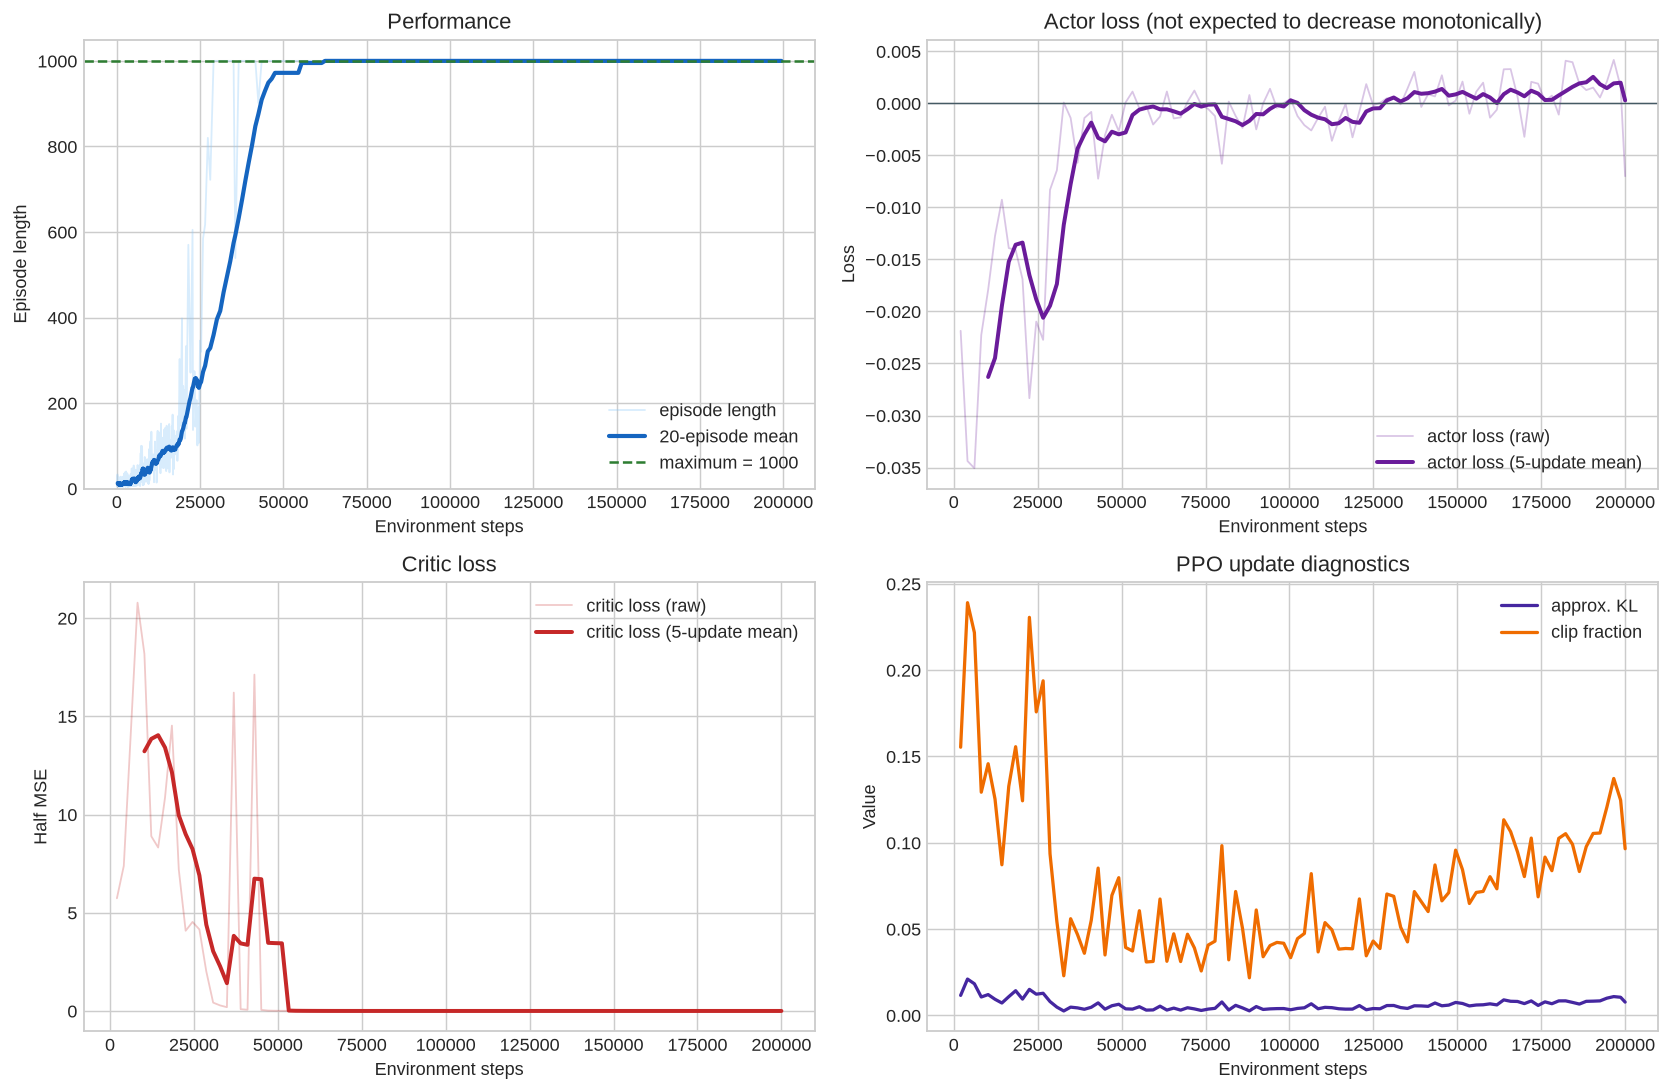

In [9]:
def history_array(result: ExperimentResult, key: str) -> np.ndarray:
    return np.asarray([row[key] for row in result.update_history], dtype=np.float64)


def moving_average(values, window: int):
    values = np.asarray(values, dtype=np.float64)
    if len(values) < window:
        return np.arange(len(values)), values
    smoothed = np.convolve(values, np.ones(window) / window, mode="valid")
    return np.arange(window - 1, len(values)), smoothed


def plot_raw_and_smooth(ax, x, y, label, color, window=5):
    ax.plot(x, y, color=color, alpha=0.25, linewidth=1, label=f"{label} (raw)")
    indices, smoothed = moving_average(y, window)
    ax.plot(np.asarray(x)[indices], smoothed, color=color, linewidth=2.2, label=f"{label} ({window}-update mean)")


def plot_training_dashboard(result: ExperimentResult):
    steps = history_array(result, "step")
    fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

    episode_steps = np.asarray(result.episode_end_steps)
    episode_lengths = np.asarray(result.episode_lengths)
    axes[0, 0].plot(episode_steps, episode_lengths, color="#90caf9", alpha=0.35, linewidth=1, label="episode length")
    indices, smoothed_lengths = moving_average(episode_lengths, 20)
    axes[0, 0].plot(episode_steps[indices], smoothed_lengths, color="#1565c0", linewidth=2.3, label="20-episode mean")
    axes[0, 0].axhline(result.config.max_episode_steps, color="#2e7d32", linestyle="--", linewidth=1.4, label="maximum = 1000")
    axes[0, 0].set(title="Performance", xlabel="Environment steps", ylabel="Episode length", ylim=(0, 1050))
    axes[0, 0].legend(frameon=False)

    plot_raw_and_smooth(axes[0, 1], steps, history_array(result, "actor_loss"), "actor loss", "#6a1b9a")
    axes[0, 1].axhline(0.0, color="#455a64", linewidth=0.8)
    axes[0, 1].set(title="Actor loss (not expected to decrease monotonically)", xlabel="Environment steps", ylabel="Loss")
    axes[0, 1].legend(frameon=False)

    plot_raw_and_smooth(axes[1, 0], steps, history_array(result, "critic_loss"), "critic loss", "#c62828")
    axes[1, 0].set(title="Critic loss", xlabel="Environment steps", ylabel="Half MSE")
    axes[1, 0].legend(frameon=False)

    axes[1, 1].plot(steps, history_array(result, "approx_kl"), color="#4527a0", linewidth=1.8, label="approx. KL")
    axes[1, 1].plot(steps, history_array(result, "clip_fraction"), color="#ef6c00", linewidth=1.8, label="clip fraction")
    axes[1, 1].set(title="PPO update diagnostics", xlabel="Environment steps", ylabel="Value")
    axes[1, 1].legend(frameon=False)

    fig.tight_layout()
    plt.show()


plot_training_dashboard(baseline_result)

## 10. Actor 与 Critic 的内部状态

左图观察探索强度。当前是一维高斯动作，所以 entropy 与 action standard deviation 高度相关。

右图中，Critic 的平均预测应逐渐跟随平均 return target；`explained variance` 更关注逐样本变化是否被解释。它接近 1 较好，接近 0 表示和只预测常数差不多，负数表示比常数基线还差。当 target 几乎成为常数、方差小于阈值时，该指标没有稳定含义，代码会记录为 `NaN`。

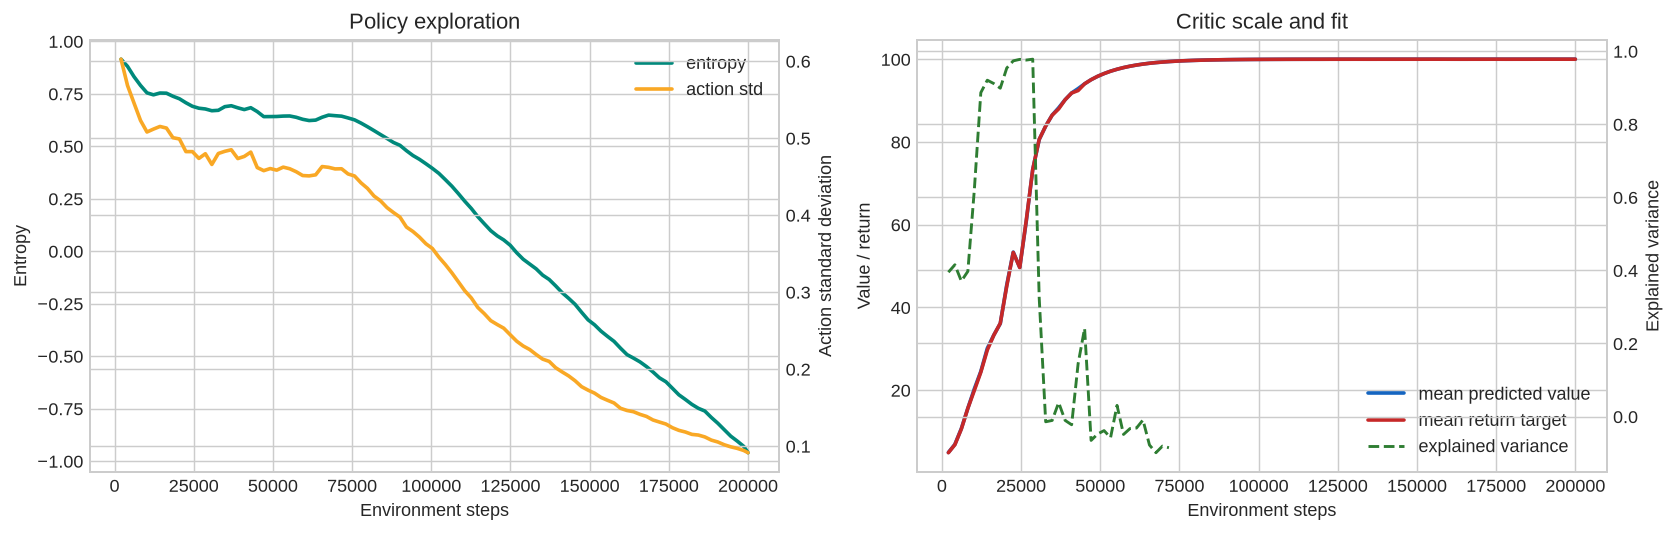

In [10]:
def plot_model_diagnostics(result: ExperimentResult):
    steps = history_array(result, "step")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

    entropy_axis = axes[0]
    std_axis = entropy_axis.twinx()
    entropy_line = entropy_axis.plot(steps, history_array(result, "entropy"), color="#00897b", linewidth=2, label="entropy")
    std_line = std_axis.plot(steps, history_array(result, "action_std"), color="#f9a825", linewidth=2, label="action std")
    entropy_axis.set(title="Policy exploration", xlabel="Environment steps", ylabel="Entropy")
    std_axis.set_ylabel("Action standard deviation")
    entropy_axis.legend(entropy_line + std_line, [line.get_label() for line in entropy_line + std_line], frameon=False)

    value_axis = axes[1]
    ev_axis = value_axis.twinx()
    predicted_line = value_axis.plot(steps, history_array(result, "mean_predicted_value"), color="#1565c0", linewidth=2, label="mean predicted value")
    target_line = value_axis.plot(steps, history_array(result, "mean_return_target"), color="#c62828", linewidth=2, label="mean return target")
    ev_line = ev_axis.plot(steps, history_array(result, "explained_variance"), color="#2e7d32", linewidth=1.6, linestyle="--", label="explained variance")
    value_axis.set(title="Critic scale and fit", xlabel="Environment steps", ylabel="Value / return")
    ev_axis.set_ylabel("Explained variance")
    lines = predicted_line + target_line + ev_line
    value_axis.legend(lines, [line.get_label() for line in lines], frameon=False, loc="best")

    fig.tight_layout()
    plt.show()


plot_model_diagnostics(baseline_result)

## 11. 确定性评估：不仅看分数，也看状态与控制力轨迹

训练时从高斯策略采样；评估时使用 Actor 均值。除了 20 个 episode 的长度，还保存第一个评估 episode 的：

- 小车位置与杆角度；
- 小车速度与杆角速度；
- Actor 输出并送入环境的控制力。

这相当于用控制系统的视角检查策略，而不是只看最终 reward。

evaluation lengths: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
mean evaluation length: 1000.0 / 1000
1000-step success rate: 100%


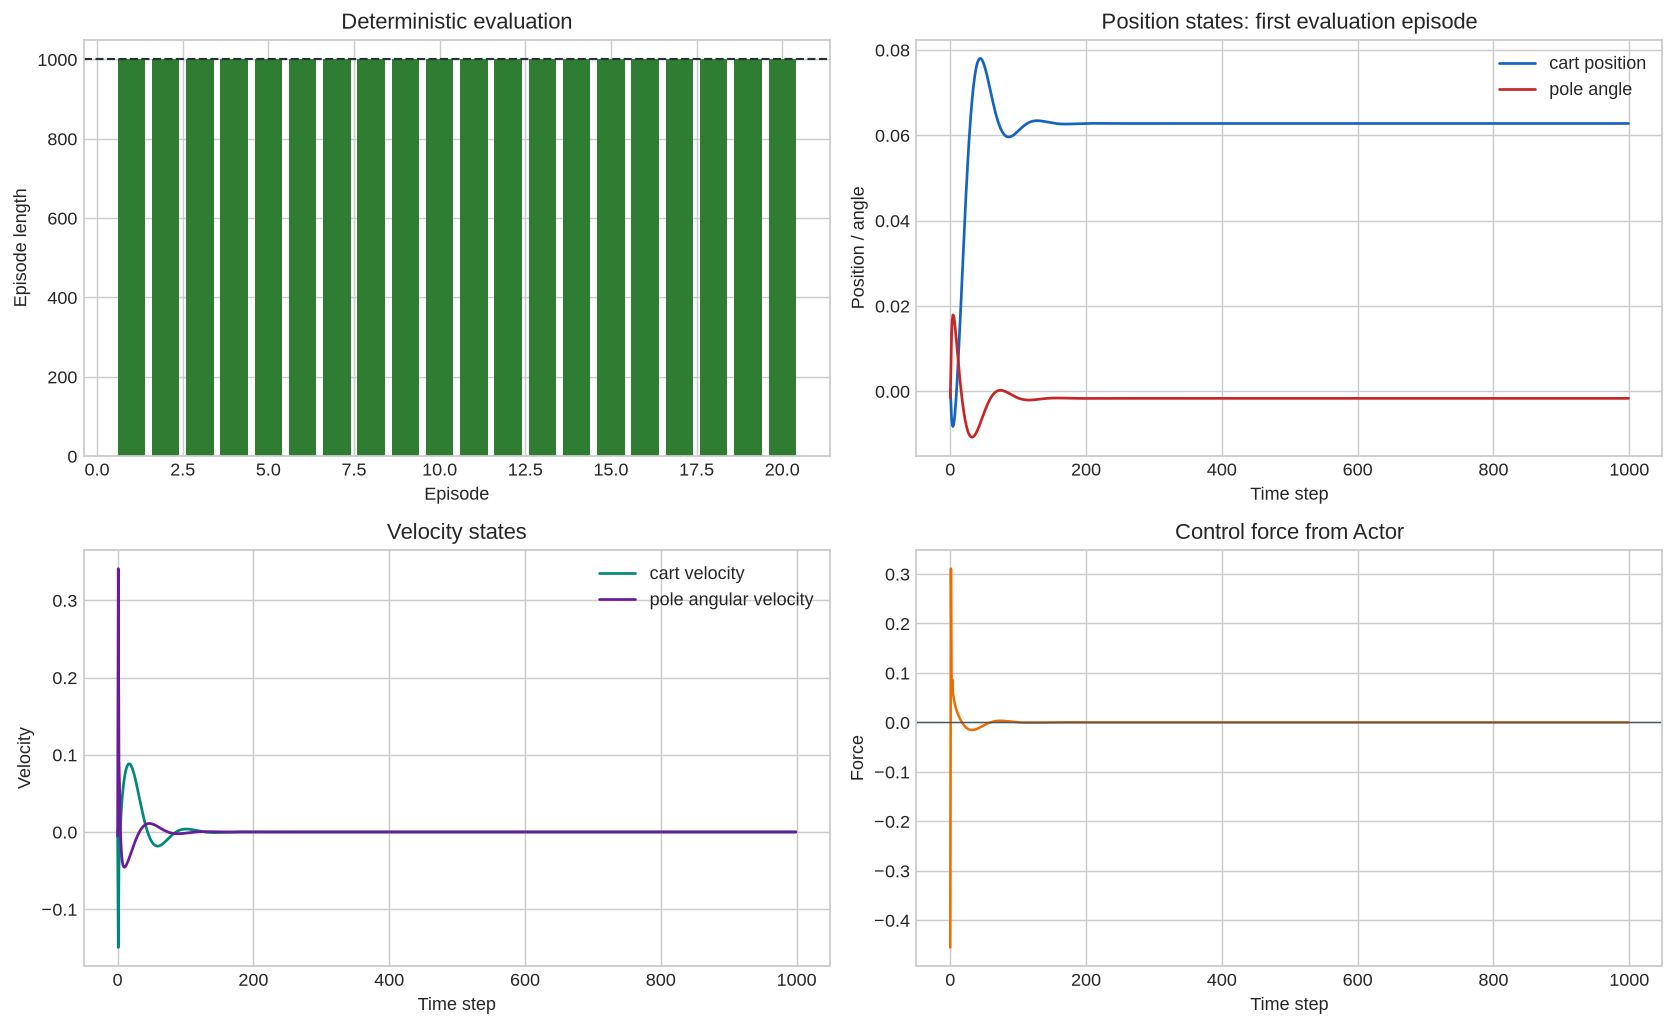

In [11]:
@dataclass
class EvaluationResult:
    episode_lengths: np.ndarray
    trajectory_observations: np.ndarray
    trajectory_actions: np.ndarray


@torch.no_grad()
def evaluate_policy(
    model: ActorCritic,
    config: Config,
    episodes: int = 20,
    seed: int = 10_000,
):
    device = next(model.parameters()).device
    eval_env = gym.make(config.env_id, max_episode_steps=config.max_episode_steps)
    action_low = torch.as_tensor(eval_env.action_space.low, dtype=torch.float32, device=device)
    action_high = torch.as_tensor(eval_env.action_space.high, dtype=torch.float32, device=device)
    episode_lengths = []
    trajectory_observations = []
    trajectory_actions = []

    for episode in range(episodes):
        obs_t, _ = eval_env.reset(seed=seed + episode)
        done = False
        episode_length = 0

        while not done:
            obs_tensor_t = torch.as_tensor(obs_t, dtype=torch.float32, device=device).unsqueeze(0)
            env_action_t = torch.clamp(model.actor_mean(obs_tensor_t)[0], action_low, action_high)

            if episode == 0:
                trajectory_observations.append(np.asarray(obs_t, dtype=np.float64).copy())
                trajectory_actions.append(env_action_t.cpu().numpy().copy())

            obs_t, _, terminated, truncated, _ = eval_env.step(env_action_t.cpu().numpy())
            episode_length += 1
            done = terminated or truncated

        episode_lengths.append(episode_length)

    eval_env.close()
    return EvaluationResult(
        episode_lengths=np.asarray(episode_lengths),
        trajectory_observations=np.asarray(trajectory_observations),
        trajectory_actions=np.asarray(trajectory_actions),
    )


def plot_evaluation(evaluation: EvaluationResult, config: Config):
    observations = evaluation.trajectory_observations
    actions = evaluation.trajectory_actions.squeeze(-1)
    time_steps = np.arange(len(observations))

    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    colors = ["#2e7d32" if length == config.max_episode_steps else "#f9a825" for length in evaluation.episode_lengths]
    axes[0, 0].bar(np.arange(1, len(evaluation.episode_lengths) + 1), evaluation.episode_lengths, color=colors)
    axes[0, 0].axhline(config.max_episode_steps, color="#263238", linestyle="--", linewidth=1.2)
    axes[0, 0].set(title="Deterministic evaluation", xlabel="Episode", ylabel="Episode length", ylim=(0, 1050))

    axes[0, 1].plot(time_steps, observations[:, 0], label="cart position", color="#1565c0")
    axes[0, 1].plot(time_steps, observations[:, 1], label="pole angle", color="#c62828")
    axes[0, 1].set(title="Position states: first evaluation episode", xlabel="Time step", ylabel="Position / angle")
    axes[0, 1].legend(frameon=False)

    axes[1, 0].plot(time_steps, observations[:, 2], label="cart velocity", color="#00897b")
    axes[1, 0].plot(time_steps, observations[:, 3], label="pole angular velocity", color="#6a1b9a")
    axes[1, 0].set(title="Velocity states", xlabel="Time step", ylabel="Velocity")
    axes[1, 0].legend(frameon=False)

    axes[1, 1].plot(time_steps, actions, color="#ef6c00", linewidth=1.4)
    axes[1, 1].axhline(0.0, color="#455a64", linewidth=0.8)
    axes[1, 1].set(title="Control force from Actor", xlabel="Time step", ylabel="Force")

    fig.tight_layout()
    plt.show()


evaluation = evaluate_policy(baseline_result.model, baseline_result.config, episodes=20)
mean_eval_length = float(evaluation.episode_lengths.mean())
success_rate = float(np.mean(evaluation.episode_lengths == baseline_result.config.max_episode_steps))
print("evaluation lengths:", evaluation.episode_lengths.tolist())
print(f"mean evaluation length: {mean_eval_length:.1f} / {baseline_result.config.max_episode_steps}")
print(f"1000-step success rate: {success_rate:.0%}")
plot_evaluation(evaluation, baseline_result.config)

## 12. 参数实验：改变 Actor 学习率，观察策略怎样学会平衡

两组实验都从 seed 1 开始，各采样 40,000 步。先猜一猜：把学习率从 0.0003 降到 0.0001，策略每次会移动多远？同样的采样预算下，哪组能撑得更久？

先运行下面的训练单元格。后面的单元格读取内存里的 `experiments`，可以单独重画。

In [12]:
experiment_base = replace(FULL_CONFIG, seed=1, total_timesteps=40_000,
                          rollout_steps=1_024, update_epochs=5)
experiments = {}
for actor_lr in (3e-4, 1e-4):
    config = replace(experiment_base, actor_lr=actor_lr)
    label = f"actor_lr = {actor_lr:g}"
    experiments[label] = train_once(config, verbose=False)
    print(label, "完成，rollout 批数 =", len(experiments[label].update_history))

actor_lr = 0.0003 完成，rollout 批数 = 40
actor_lr = 0.0001 完成，rollout 批数 = 40


### 先读横轴

`step` 数的是调用训练环境 `env.step()` 的累计次数。采完一批，`ppo_update` 会反复使用这批数据；`train_once` 随后向 `update_history` 写一行。默认实验的第一批有 1024 条样本，每个 epoch 分成 16 个大小为 64 的 mini-batch，5 个 epoch 共做 80 次 mini-batch 更新。整个过程中横坐标停在 1024。

下面打印前两批与最后一批。图上每个诊断圆点对应这样的一行，点间连线只帮助阅读。回合长度另有记录时机，每次回合结束才有一个长度。

In [13]:
history = next(iter(experiments.values())).update_history
for index in sorted({0, min(1, len(history) - 1), len(history) - 1}):
    row = history[index]
    print(f"rollout {index + 1:2d} | 累计环境步 {int(row['step']):6d} | "
          f"批内平均 KL {row['approx_kl']:.5f}")

rollout  1 | 累计环境步   1024 | 批内平均 KL 0.00967
rollout  2 | 累计环境步   2048 | 批内平均 KL 0.01198
rollout 40 | 累计环境步  40000 | 批内平均 KL 0.00011


### ① 学会平衡了吗？

左图在每个已结束回合的终点画出最近 20 回合的平均长度。右图让各组最终策略在相同的 20 个初始条件下使用均值动作，每点是一回合。先比较左图同一训练步数的成绩，再看最终策略是否有容易倒下的初始条件。

actor_lr = 0.0003: 评估平均 1000.0 步，跑满 20/20
actor_lr = 0.0001: 评估平均 1000.0 步，跑满 20/20


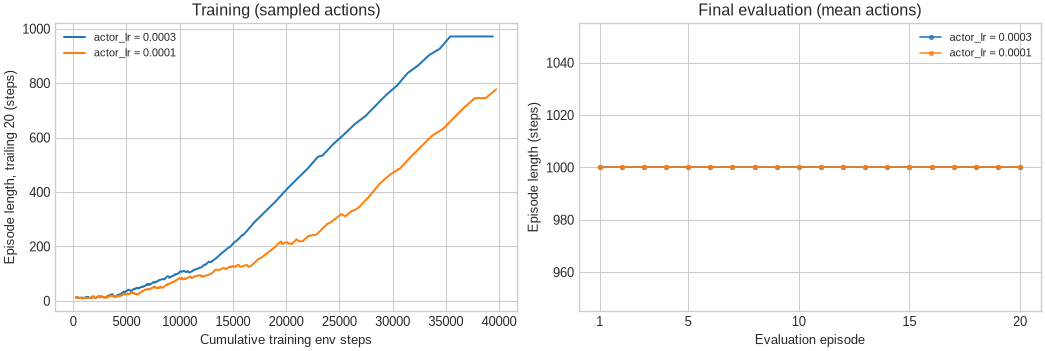

In [14]:
fig, (ax_train, ax_eval) = plt.subplots(1, 2, figsize=(11, 3.7), constrained_layout=True)
for label, result in experiments.items():
    lengths = np.asarray(result.episode_lengths)
    end_steps = np.asarray(result.episode_end_steps)
    if len(lengths) >= 20:
        indices, mean20 = moving_average(lengths, 20)
        ax_train.plot(end_steps[indices], mean20, label=label)
    ev = evaluate_policy(result.model, result.config, episodes=20, seed=10_000)
    ax_eval.plot(np.arange(1, 21), ev.episode_lengths, marker=".", label=label, alpha=0.75)
    print(f"{label}: 评估平均 {ev.episode_lengths.mean():.1f} 步，"
          f"跑满 {np.count_nonzero(ev.episode_lengths == result.config.max_episode_steps)}/20")
ax_train.set(title="Training (sampled actions)", xlabel="Cumulative training env steps",
             ylabel="Episode length, trailing 20 (steps)")
ax_eval.set(title="Final evaluation (mean actions)", xlabel="Evaluation episode",
            ylabel="Episode length (steps)", xticks=[1, 5, 10, 15, 20])
for ax in (ax_train, ax_eval):
    ax.legend(fontsize=8)
plt.show()

### ② 策略移动了多少？③ 动作探索有多宽？

先对照 KL 与越界比例，再看两组学习曲线在哪一段开始分开。`clip_fraction` 统计概率密度比落在裁剪区间外的比例。它对正负 advantage 都计数。下排的标准差表示在同一观测下采样动作的波动幅度；一维高斯的微分熵随标准差增大而上升。KL、越界比例和熵取批内各 mini-batch 的均值，标准差读取更新后的参数。

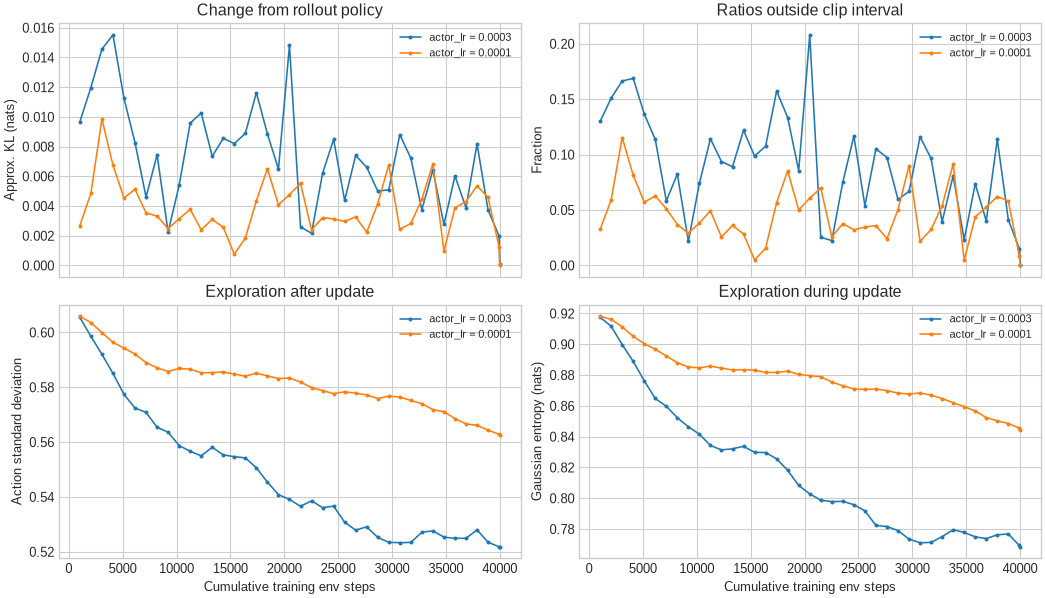

In [15]:
def plot_update_metrics(results, panels):
    fig, axes = plt.subplots((len(panels) + 1) // 2, 2, figsize=(11, 6.3),
                             sharex=True, squeeze=False, constrained_layout=True)
    for ax, (title, key, unit) in zip(axes.flat, panels):
        for label, result in results.items():
            ax.plot(history_array(result, "step"), history_array(result, key),
                    marker=".", markersize=4, linewidth=1.2, label=label)
        ax.set(title=title, ylabel=unit)
        ax.legend(fontsize=8)
    for ax in axes[-1]:
        ax.set_xlabel("Cumulative training env steps")
    plt.show()

plot_update_metrics(experiments, [
    ("Change from rollout policy", "approx_kl", "Approx. KL (nats)"),
    ("Ratios outside clip interval", "clip_fraction", "Fraction"),
    ("Exploration after update", "action_std", "Action standard deviation"),
    ("Exploration during update", "entropy", "Gaussian entropy (nats)"),
])

### ④ Critic 跟上了吗？⑤ Actor loss 怎样变化？

先对照预测值和 target 的平均水平，再看逐样本误差。价值诊断在本批更新后对同一批数据计算；explained variance 遇到几乎恒定的 target 会留空。两个 loss 都是各 mini-batch 的平均值。Actor loss 依赖本轮的旧策略和标准化 advantage，跨轮解读时要同时看任务成绩。

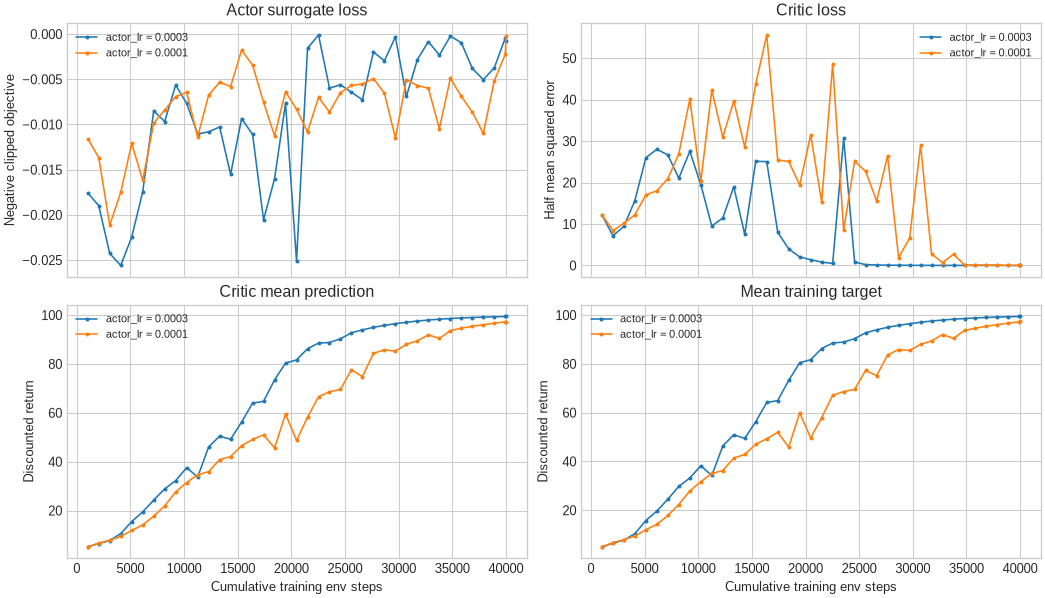

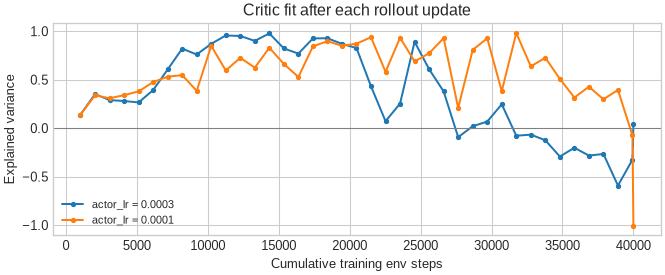

In [16]:
plot_update_metrics(experiments, [
    ("Actor surrogate loss", "actor_loss", "Negative clipped objective"),
    ("Critic loss", "critic_loss", "Half mean squared error"),
    ("Critic mean prediction", "mean_predicted_value", "Discounted return"),
    ("Mean training target", "mean_return_target", "Discounted return"),
])

fig, ax = plt.subplots(figsize=(7, 2.9), constrained_layout=True)
for label, result in experiments.items():
    ax.plot(history_array(result, "step"), history_array(result, "explained_variance"),
            marker=".", label=label)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set(xlabel="Cumulative training env steps", ylabel="Explained variance",
       title="Critic fit after each rollout update")
ax.legend(fontsize=8)
plt.show()

**写下你的观察。** 选两条性能曲线分开的一段，记下相同环境步数下的平均回合长度，再找同时段的 KL 和越界比例。最后用相同初始条件下的评估结果检查你的判断。更换 seed 可以检验这个现象是否能重复出现。

## 13. 你的复现工作流

建议不要一开始复制整份训练器。一次只重写一个边界清楚的模块：

```python
def my_compute_gae(...):
    ...

check_compute_gae(my_compute_gae)
```

同样可以使用：

```python
check_actor_critic(MyActorCritic)
check_ppo_loss(my_ppo_clipped_actor_loss)
```

推荐顺序：

1. 重写 `compute_gae`，通过四个数值案例。
2. 重写 `ppo_clipped_actor_loss`，通过 ratio、clip 和梯度检查。
3. 重写 `ActorCritic`，通过形状和梯度检查。
4. 对照 `print_rollout_preview()`，重写 rollout。
5. 用 `QUICK_CONFIG` 接通训练闭环。
6. 最后使用 `FULL_CONFIG`，确认自己的实现能达到接近 1000 步。

调试时要区分两类失败：**检查器失败**通常是数学、形状或边界处理错误；检查器全部通过但训练不收敛，才重点检查优化超参数、随机性和长期数据流。

## 14. 如何阅读这些曲线

- **Episode length** 是最终性能指标；本环境每步奖励为 1，所以它也等于 episode return。
- **Actor loss** 的绝对值没有跨 update 的固定含义，主要用于发现突变、NaN 或更新异常。
- **Critic loss** 受 return 尺度影响；和 `mean return target`、`explained variance` 一起看。
- **Approx. KL / clip fraction** 长期很大，通常说明策略更新过猛；接近零则可能更新过小。
- **Entropy / action std** 反映探索强度，但并非越大越好。
- **状态与控制力轨迹** 用来判断策略虽然得分高，是否仍存在漂移、抖动或过大的控制输入。
- 本环境的奖励只关心倒立摆是否保持健康，没有要求小车回到零点；因此最终停在一个小的非零位置不代表训练失败。若希望回中心，需要修改奖励或环境任务定义。

这仍是教学实现：单环境、未截断高斯采样后再裁剪动作、无观测归一化、无学习率退火。等这条主线完全看懂，再迁移到更复杂的机器人任务。